# 🚀 VoiceGuard ML - CNN Training (Google Colab + Drive)

**Train with GPU using data from Google Drive (no upload needed!)**

## Setup Instructions:

1. **Upload data to Google Drive FIRST**
   - Go to drive.google.com
   - Upload `mel_3ch.zip` (or the unzipped folder)
   - Note the path (e.g., `/content/drive/MyDrive/mel_3ch.zip`)

2. **Upload this notebook to Colab**
   - Go to colab.research.google.com
   - File → Upload notebook

3. **Enable GPU**
   - Runtime → Change runtime type → GPU

4. **Run all cells**

---

## Step 1: Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

print("✅ Google Drive mounted!")

Mounted at /content/drive
✅ Google Drive mounted!


## Step 2: Extract Data from Drive

In [2]:
import zipfile
import os

# UPDATE THIS PATH to where you uploaded mel_3ch.zip in Google Drive
ZIP_PATH = "/content/drive/MyDrive/mel_3ch.zip"  # Change this!

# Check if file exists
if not os.path.exists(ZIP_PATH):
    print("❌ File not found!")
    print(f"   Looking for: {ZIP_PATH}")
    print("\n📁 Available files in MyDrive:")
    !ls -lh /content/drive/MyDrive/
    print("\n⚠️ Update ZIP_PATH above to match your file location")
else:
    print(f"✅ Found: {ZIP_PATH}")

    # Extract
    print("📦 Extracting (this may take 1-2 minutes)...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall('/content')

    print("✅ Extracted!")

    # Set base directory
    BASE = "/content/processed/mel_3ch"  # Adjust if different

    # Verify structure
    if os.path.exists(BASE):
        print(f"\n✅ Data ready at: {BASE}")
        !ls -lh {BASE}
    else:
        print("\n⚠️ Extracted structure might be different")
        print("   Available directories:")
        !ls -lh /content/

✅ Found: /content/drive/MyDrive/mel_3ch.zip
📦 Extracting (this may take 1-2 minutes)...
✅ Extracted!

✅ Data ready at: /content/processed/mel_3ch
total 1.5M
drwxr-xr-x 2 root root 752K Nov 30 15:04 fake
drwxr-xr-x 2 root root 692K Nov 30 15:04 real


## Alternative: If you uploaded the unzipped folder directly

In [3]:
# Uncomment if you uploaded the folder (not zip) to Drive
# BASE = "/content/drive/MyDrive/voiceguard-ml/processed/mel_3ch"
# print(f"Using data from Drive: {BASE}")

## Step 3: Install Dependencies

In [4]:
!pip install -q librosa scikit-learn tqdm

## Step 4: Verify GPU

In [5]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

if tf.config.list_physical_devices('GPU'):
    print("✅ GPU is enabled! Training will be FAST! 🚀")
else:
    print("⚠️ No GPU detected. Go to Runtime → Change runtime type → GPU")

TensorFlow version: 2.19.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✅ GPU is enabled! Training will be FAST! 🚀


## Step 5: Training Code

In [6]:
import glob
import numpy as np
from tqdm import tqdm
from tensorflow.keras import layers, models, optimizers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score
import matplotlib.pyplot as plt

def load_dataset(base_dir):
    """Load .npy mel arrays into X,y"""
    real_files = sorted(glob.glob(os.path.join(base_dir, "real", "*.npy")))
    fake_files = sorted(glob.glob(os.path.join(base_dir, "fake", "*.npy")))

    print("FOUND:", len(real_files), "real,", len(fake_files), "fake")

    X, y = [], []

    for f in tqdm(real_files, desc="Loading real"):
        X.append(np.load(f))
        y.append(1)

    for f in tqdm(fake_files, desc="Loading fake"):
        X.append(np.load(f))
        y.append(0)

    return np.array(X), np.array(y)

def build_cnn(input_shape):
    """CNN model for 128×128×C spectrograms"""
    inp = layers.Input(shape=input_shape)

    x = layers.Conv2D(32, (3,3), padding='same', activation='relu')(inp)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPool2D((2,2))(x)

    x = layers.Conv2D(64, (3,3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPool2D((2,2))(x)

    x = layers.Conv2D(128, (3,3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPool2D((2,2))(x)

    x = layers.Flatten()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.3)(x)

    out = layers.Dense(1, activation='sigmoid')(x)

    model = models.Model(inp, out)
    model.compile(
        optimizer=optimizers.Adam(1e-4),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
    )
    return model

## Step 6: Load Data

In [7]:
print("\n=== LOADING DATASET ===")
X, y = load_dataset(BASE)

print("Raw X shape:", X.shape)

if X.ndim == 3:
    X = np.expand_dims(X, -1)
X = X.astype("float32")

# Split: 70/20/10
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=1/3, random_state=42, stratify=y_temp)

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")


=== LOADING DATASET ===
FOUND: 6978 real, 6978 fake


Loading fake: 100%|██████████| 6978/6978 [00:07<00:00, 947.00it/s]


Raw X shape: (13956, 128, 128, 3)
Train: (9769, 128, 128, 3), Val: (2791, 128, 128, 3), Test: (1396, 128, 128, 3)


## Step 7: Build Model

In [8]:
input_shape = X_train.shape[1:]
model = build_cnn(input_shape)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,705 (16.36 MB)

 Trainable params: 4,288,257 (16.36 MB)

 Non-trainable params: 448 (1.75 KB)

## Step 8: Train Model

In [9]:
# Callbacks - save to Drive to avoid disk space issues
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/content/drive/MyDrive/best_model.h5",  # Save to Drive!
    monitor="val_auc",
    mode="max",
    save_best_only=True,
    verbose=1
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", patience=3, factor=0.5, verbose=1
)
early = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=6, restore_best_weights=True, verbose=1
)

print("\n=== TRAINING MODEL ===")
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[checkpoint, reduce_lr, early],
    verbose=1
)


=== TRAINING MODEL ===
Epoch 1/30
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.7452 - auc: 0.8163 - loss: 0.6223
Epoch 1: val_auc improved from -inf to 0.50000, saving model to /content/drive/MyDrive/best_model.h5


306/306 ━━━━━━━━━━━━━━━━━━━━ 27s 55ms/step - accuracy: 0.7456 - auc: 0.8167 - loss: 0.6214 - val_accuracy: 0.4998 - val_auc: 0.5000 - val_loss: 4.7840 - learning_rate: 1.0000e-04
Epoch 2/30
305/306 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9802 - auc: 0.9971 - loss: 0.0690
Epoch 2: val_auc improved from 0.50000 to 0.99922, saving model to /content/drive/MyDrive/best_model.h5


306/306 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9802 - auc: 0.9971 - loss: 0.0689 - val_accuracy: 0.9656 - val_auc: 0.9992 - val_loss: 0.0856 - learning_rate: 1.0000e-04
Epoch 3/30
305/306 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9922 - auc: 0.9995 - loss: 0.0273
Epoch 3: val_auc improved from 0.99922 to 0.99986, saving model to /content/drive/MyDrive/best_model.h5


306/306 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9922 - auc: 0.9995 - loss: 0.0273 - val_accuracy: 0.9961 - val_auc: 0.9999 - val_loss: 0.0176 - learning_rate: 1.0000e-04
Epoch 4/30
305/306 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9887 - auc: 0.9993 - loss: 0.0335
Epoch 4: val_auc improved from 0.99986 to 0.99990, saving model to /content/drive/MyDrive/best_model.h5


306/306 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9887 - auc: 0.9993 - loss: 0.0334 - val_accuracy: 0.9953 - val_auc: 0.9999 - val_loss: 0.0149 - learning_rate: 1.0000e-04
Epoch 5/30
304/306 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9974 - auc: 1.0000 - loss: 0.0087
Epoch 5: val_auc did not improve from 0.99990
306/306 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.9974 - auc: 1.0000 - loss: 0.0087 - val_accuracy: 0.9781 - val_auc: 0.9985 - val_loss: 0.0583 - learning_rate: 1.0000e-04
Epoch 6/30
305/306 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9973 - auc: 1.0000 - loss: 0.0093
Epoch 6: val_auc did not improve from 0.99990
306/306 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9973 - auc: 1.0000 - loss: 0.0093 - val_accuracy: 0.9950 - val_auc: 0.9996 - val_loss: 0.0129 - learning_rate: 1.0000e-04
Epoch 7/30
305/306 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9988 - auc: 1.0000 - loss: 0.0042
Epoch 7: val_auc did not improve from 0.99990
306/306 ━━━━━━━━━━━━━━━━━

...

306/306 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - accuracy: 0.9996 - auc: 1.0000 - loss: 0.0016 - val_accuracy: 0.9982 - val_auc: 1.0000 - val_loss: 0.0048 - learning_rate: 1.0000e-04
Epoch 13/30
305/306 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9997 - auc: 1.0000 - loss: 0.0013
Epoch 13: val_auc did not improve from 0.99998
306/306 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.9997 - auc: 1.0000 - loss: 0.0013 - val_accuracy: 0.9946 - val_auc: 1.0000 - val_loss: 0.0134 - learning_rate: 1.0000e-04
Epoch 14/30
304/306 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9989 - auc: 1.0000 - loss: 0.0034
Epoch 14: val_auc improved from 0.99998 to 0.99999, saving model to /content/drive/MyDrive/best_model.h5


306/306 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - accuracy: 0.9989 - auc: 1.0000 - loss: 0.0034 - val_accuracy: 0.9979 - val_auc: 1.0000 - val_loss: 0.0047 - learning_rate: 1.0000e-04
Epoch 15/30
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9977 - auc: 0.9996 - loss: 0.0082
Epoch 15: val_auc did not improve from 0.99999
306/306 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9977 - auc: 0.9996 - loss: 0.0082 - val_accuracy: 0.9961 - val_auc: 0.9996 - val_loss: 0.0111 - learning_rate: 1.0000e-04
Epoch 16/30
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9988 - auc: 1.0000 - loss: 0.0038
Epoch 16: val_auc did not improve from 0.99999
306/306 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.9988 - auc: 1.0000 - loss: 0.0038 - val_accuracy: 0.9964 - val_auc: 0.9999 - val_loss: 0.0115 - learning_rate: 1.0000e-04
Epoch 17/30
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9997 - auc: 1.0000 - loss: 0.0021
Epoch 17: val_auc improved from 0.99999 to 1.00000, saving model 

306/306 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.9997 - auc: 1.0000 - loss: 0.0021 - val_accuracy: 0.9979 - val_auc: 1.0000 - val_loss: 0.0039 - learning_rate: 1.0000e-04
Epoch 18/30
305/306 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 3.8743e-04
Epoch 18: val_auc did not improve from 1.00000
306/306 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 3.9013e-04 - val_accuracy: 0.9968 - val_auc: 0.9993 - val_loss: 0.0113 - learning_rate: 1.0000e-04
Epoch 19/30
305/306 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9991 - auc: 0.9995 - loss: 0.0056
Epoch 19: val_auc did not improve from 1.00000
306/306 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.9991 - auc: 0.9995 - loss: 0.0056 - val_accuracy: 0.9914 - val_auc: 0.9993 - val_loss: 0.0259 - learning_rate: 1.0000e-04
Epoch 20/30
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9998 - auc: 1.0000 - loss: 0.0012
Epoch 20: val_auc did not improve from 1.00000

Epoch 20: 

306/306 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 1.0242e-04 - val_accuracy: 0.9982 - val_auc: 1.0000 - val_loss: 0.0036 - learning_rate: 5.0000e-05
Epoch 24/30
304/306 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 1.1319e-04
Epoch 24: val_auc did not improve from 1.00000
306/306 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 1.1314e-04 - val_accuracy: 0.9982 - val_auc: 1.0000 - val_loss: 0.0034 - learning_rate: 5.0000e-05
Epoch 25/30
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 6.4129e-05
Epoch 25: val_auc did not improve from 1.00000
306/306 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 6.4202e-05 - val_accuracy: 0.9993 - val_auc: 1.0000 - val_loss: 0.0025 - learning_rate: 5.0000e-05
Epoch 26/30
306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 7.9919e-05
Epoch 26: val_auc improved from 1.00000 to

306/306 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 7.9887e-05 - val_accuracy: 0.9979 - val_auc: 1.0000 - val_loss: 0.0055 - learning_rate: 5.0000e-05
Epoch 27/30
305/306 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9998 - auc: 1.0000 - loss: 6.0072e-04
Epoch 27: val_auc did not improve from 1.00000
306/306 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.9998 - auc: 1.0000 - loss: 6.0843e-04 - val_accuracy: 0.9896 - val_auc: 0.9981 - val_loss: 0.0357 - learning_rate: 5.0000e-05
Epoch 28/30
305/306 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9975 - auc: 1.0000 - loss: 0.0065
Epoch 28: val_auc did not improve from 1.00000

Epoch 28: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.
306/306 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9975 - auc: 1.0000 - loss: 0.0065 - val_accuracy: 0.9975 - val_auc: 0.9996 - val_loss: 0.0071 - learning_rate: 5.0000e-05
Epoch 29/30
305/306 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 1.0000 - auc

## Step 9: Evaluate

In [10]:
# Save final model to Drive
model.save("/content/drive/MyDrive/voiceguard_cnn.h5")
print("\n✅ Saved models to Google Drive!")
print("   - best_model.h5")
print("   - voiceguard_cnn.h5")

# Evaluate
print("\n=== TESTING MODEL ===")
y_prob = model.predict(X_test).ravel()
y_pred = (y_prob >= 0.5).astype(int)

auc_score = roc_auc_score(y_test, y_prob)
print(f"\n🎯 AUC = {auc_score:.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))

print("\n=== TRAINING COMPLETE ===")
print(f"✅ Models saved in Google Drive (MyDrive folder)")


✅ Saved models to Google Drive!
   - best_model.h5
   - voiceguard_cnn.h5

=== TESTING MODEL ===
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step

🎯 AUC = 0.9998

Confusion Matrix:
[[698   0]
 [  1 697]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9986    1.0000    0.9993       698
           1     1.0000    0.9986    0.9993       698

    accuracy                         0.9993      1396
   macro avg     0.9993    0.9993    0.9993      1396
weighted avg     0.9993    0.9993    0.9993      1396


=== TRAINING COMPLETE ===
✅ Models saved in Google Drive (MyDrive folder)


## Step 10: Plot Training History

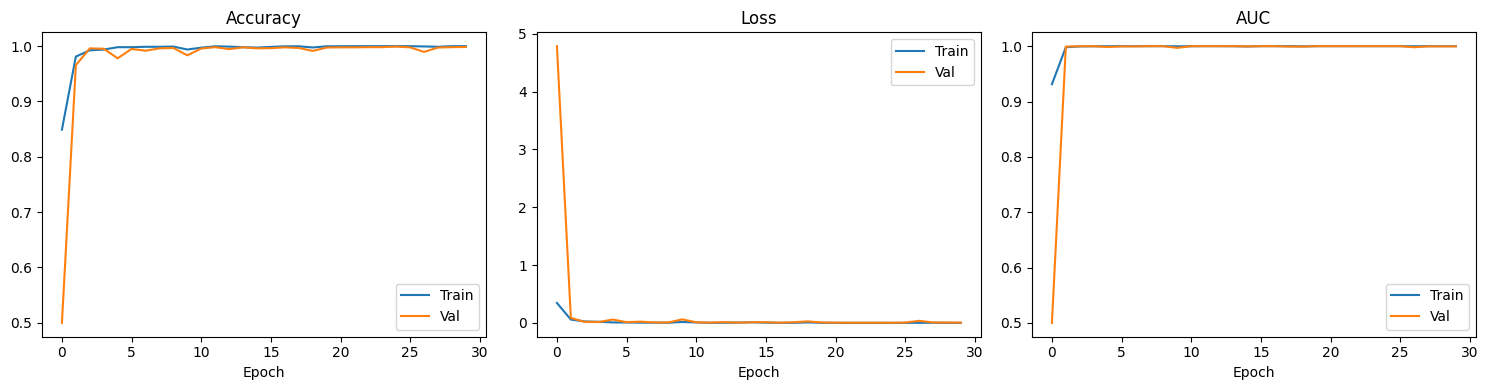

✅ Saved training_history.png to Google Drive


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(history.history['accuracy'], label='Train')
axes[0].plot(history.history['val_accuracy'], label='Val')
axes[0].set_title('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history.history['loss'], label='Train')
axes[1].plot(history.history['val_loss'], label='Val')
axes[1].set_title('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()

axes[2].plot(history.history['auc'], label='Train')
axes[2].plot(history.history['val_auc'], label='Val')
axes[2].set_title('AUC')
axes[2].set_xlabel('Epoch')
axes[2].legend()

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/training_history.png', dpi=150)
plt.show()

print("✅ Saved training_history.png to Google Drive")

## ✅ Done!

Your trained models are saved in **Google Drive → MyDrive**:
- `best_model.h5` (use this one!)
- `voiceguard_cnn.h5`
- `training_history.png`

You can access them anytime from drive.google.com!